In [1]:
#  Benjamin Wollant
#  March 11, 2024
#  Updated May 2, 2025
#  This is a script for simulating single molecule kinetics via a Poisson Process for a nanoswitch consturct
#  

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.linalg import expm
from matplotlib.colors import ListedColormap, BoundaryNorm



In [3]:
#Functions for Simulation
#gen_target concentration
def gen_target(steps: np.ndarray, number_timepoints: int, time_step: float):
    target = np.zeros(number_timepoints)
    
    for s in steps:
        profile_type = s.size
        start = int(60*round(s[0]/time_step))
        stop = int(60*round(s[1]/time_step))  
        
        match profile_type:
            case 3: #step functions between times at indices 0 and 1, value of index 2
                target[start:stop] += s[2]
            case 4: #linear functions between times at indices 0 and 1, values ramp from index 2 to index 3 linearly
                slant = np.linspace(s[2], s[3], stop-start)
                target[start:stop] += slant
    
    return target

#mechanical actuation, i.e. forced vs unforced
def gen_mode(steps: np.ndarray, number_timepoints: int, time_step: float):
    mode = np.zeros(number_timepoints)
    
    for s in steps:
        start = int(60*round(s[0]/time_step))
        stop = int(60*round(s[1]/time_step))  
        mode[start:stop] = 1 # 1 for mode F, 0 for mode U
        
    return mode

def modified_gillespie(target: np.ndarray, mechanical_force: np.ndarray, number_timepoints: int, time_step: float, initial_state: np.ndarray, rates: list): 
    n_switches = initial_state.size
    current_state = initial_state.copy()
    #0- A (unbound)
    #1- B1 (bound to Ab1)
    #2- B2 (bound to Ab2)
    #3- C (bound to Ab1 and Ab2)
    #4- D (two targets bound)
    kon1 = rates[0] # 1/(M*s)
    kon2 = rates[1]  # 1/(M*s)
    koff1 = rates[2] #1/s
    koff2 = rates[3] #1/s
    Ceff = rates[4]  # M
    koff1M = rates[5] #1/s
    koff2M = rates[6]  #1/s
    

    state_traces = np.zeros((n_switches,1+number_timepoints))
    state_traces[:,0] = current_state.copy()
    
    # Modified Gillespie Algorithm
    #   no variable timestep, just compute probability of transition at uniform time step and randomly sample
    for i in range(number_timepoints):
        
        match mechanical_force[i]:
            case 0: #no mechanical force applied
                
            
                for j in range(n_switches):
                    r = np.random.rand()
                    
                    match current_state[j]:
                        case 0: #if unbound 
                            p_B1 = kon1*target[i]*time_step
                            p_B2 = kon2*target[i]*time_step
                            if r < p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                
                        case 1: #if bound to Ab1
                            p_A = koff1*time_step
                            p_C = Ceff*kon2*time_step
                            p_D = kon2*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < (p_A + p_C):
                                current_state[j] = 3
                            elif (p_A + p_C) < r < (p_A + p_C + p_D):
                                current_state[j] = 4
                        
                        case 2: #if bound to Ab2
                            p_A = koff2*time_step
                            p_C = Ceff*kon1*time_step
                            p_D = kon1*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < p_A + p_C:
                                current_state[j] = 3
                            elif p_A + p_C < r < p_A + p_C + p_D:
                                current_state[j] = 4
                        
                        case 3: #bound to Ab1 and Ab2 (closed)
                            p_B1 = koff2*time_step
                            p_B2 = koff1*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                        
                        case 4: #Ab1 and Ab2 bound separately
                            p_B1 = koff2*time_step
                            p_B2 = koff1*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
            
            case 1: #mechanical force applied
                
            
                for j in range(n_switches):
                    r = np.random.rand()
                    
                    match current_state[j]:
                        case 0: #if unbound 
                            p_B1 = kon1*target[i]*time_step
                            p_B2 = kon2*target[i]*time_step
                            if r < p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                
                        case 1: #if bound to Ab1
                            p_A = koff1*time_step
                            p_D = kon2*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < (p_A + p_D):
                                current_state[j] = 4
                            
                        
                        case 2: #if bound to Ab2
                            p_A = koff2*time_step
                            p_D = kon1*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < (p_A + p_D):
                                current_state[j] = 4
                            
                        
                        case 3: #bound to Ab1 and Ab2 (closed)
                            p_B1 = koff2M*time_step
                            p_B2 = koff1M*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                        
                        case 4: #Ab1 and Ab2 bound separately
                            p_B1 = koff2*time_step
                            p_B2 = koff1*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2        
            
        state_traces[:,i+1] = current_state
    return state_traces

def modified_gillespie_homodimer(target: np.ndarray, mechanical_force: np.ndarray, number_timepoints: int, time_step: float, initial_state: np.ndarray, rates: list): 
    n_switches = initial_state.size
    current_state = initial_state.copy()
    #0- A (unbound)
    #1- B1 (bound to Ab1)
    #2- B2 (bound to Ab2)
    #3- C (bound to Ab1 and Ab2)
    #4- D (two targets bound)
    kon1 = rates[0] # 1/(M*s)
    kon2 = rates[1]  # 1/(M*s)
    koff1 = rates[2] #1/s
    koff2 = rates[3] #1/s
    Ceff = rates[4]  # M
    koff1M = rates[5] #1/s
    koff2M = rates[6]  #1/s
    

    state_traces = np.zeros((n_switches,1+number_timepoints))
    state_traces[:,0] = current_state.copy()
    
    # Modified Gillespie Algorithm
    #   no variable timestep, just compute probability of transition at uniform time step and randomly sample
    for i in range(number_timepoints):
        
        match mechanical_force[i]:
            case 0: #no mechanical force applied
                
            
                for j in range(n_switches):
                    r = np.random.rand()
                    
                    match current_state[j]:
                        case 0: #if unbound 
                            p_B1 = 2*kon1*target[i]*time_step
                            p_B2 = 2*kon2*target[i]*time_step
                            if r < p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                
                        case 1: #if bound to Ab1
                            p_A = koff1*time_step
                            p_C = Ceff*kon2*time_step
                            p_D = 2*kon2*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < (p_A + p_C):
                                current_state[j] = 3
                            elif (p_A + p_C) < r < (p_A + p_C + p_D):
                                current_state[j] = 4
                        
                        case 2: #if bound to Ab2
                            p_A = koff2*time_step
                            p_C = Ceff*kon1*time_step
                            p_D = 2*kon1*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < p_A + p_C:
                                current_state[j] = 3
                            elif p_A + p_C < r < p_A + p_C + p_D:
                                current_state[j] = 4
                        
                        case 3: #bound to Ab1 and Ab2 (closed)
                            p_B1 = koff2*time_step
                            p_B2 = koff1*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                        
                        case 4: #Ab1 and Ab2 bound separately
                            p_B1 = koff2*time_step
                            p_B2 = koff1*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
            
            case 1: #mechanical force applied
                
            
                for j in range(n_switches):
                    r = np.random.rand()
                    
                    match current_state[j]:
                        case 0: #if unbound 
                            p_B1 = 2*kon1*target[i]*time_step
                            p_B2 = 2*kon2*target[i]*time_step
                            if r < p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                
                        case 1: #if bound to Ab1
                            p_A = koff1*time_step
                            p_D = 2*kon2*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < (p_A + p_D):
                                current_state[j] = 4
                            
                        
                        case 2: #if bound to Ab2
                            p_A = koff2*time_step
                            p_D = 2*kon1*target[i]*time_step
                            if r < p_A:
                                current_state[j] = 0
                            elif p_A < r < (p_A + p_D):
                                current_state[j] = 4
                            
                        
                        case 3: #bound to Ab1 and Ab2 (closed)
                            p_B1 = koff2M*time_step
                            p_B2 = koff1M*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2
                        
                        case 4: #Ab1 and Ab2 bound separately
                            p_B1 = koff2*time_step
                            p_B2 = koff1*time_step
                            if r<p_B1:
                                current_state[j] = 1
                            elif p_B1 < r < (p_B1 + p_B2):
                                current_state[j] = 2        
            
        state_traces[:,i+1] = current_state
    return state_traces


def gen_ensembles(state_traces: np.ndarray):
    switch_tracesA = (state_traces == 0).astype(int)
    switch_tracesB1 = (state_traces == 1).astype(int)
    switch_tracesB2 = (state_traces == 2).astype(int)
    switch_tracesC = (state_traces == 3).astype(int)
    switch_tracesD = (state_traces == 4).astype(int)

    ensemble_A = np.sum(switch_tracesA,0)
    ensemble_B1 = np.sum(switch_tracesB1,0)
    ensemble_B2 = np.sum(switch_tracesB2,0)
    ensemble_C = np.sum(switch_tracesC,0)
    ensemble_D = np.sum(switch_tracesD,0)
    
    return [ensemble_A, ensemble_B1, ensemble_B2, ensemble_C, ensemble_D]

def plot_ensemble_traces(ensemble_A, ensemble_B1, ensemble_B2, ensemble_C, ensemble_D, target, mode, t, n_switches):
    plt.rcParams['font.family'] = 'serif'         # 'sans-serif', 'serif', 'monospace', etc.
    plt.rcParams['font.serif'] = ['Times New Roman']  # or 'Georgia', 'Palatino', etc.
    
    plt.figure(figsize=(12, 4))

    plt.plot(t/3600,ensemble_A[0:-1]/n_switches, color='#0000FF', label='A')
    plt.plot(t/3600,ensemble_B1[0:-1]/n_switches, color='#15B01A', label='B1')
    plt.plot(t/3600,ensemble_B2[0:-1]/n_switches, color='#BBF90F', label='B2')
    plt.plot(t/3600,ensemble_C[0:-1]/n_switches, color='#E50000', label='C')
    plt.plot(t/3600,ensemble_D[0:-1]/n_switches, color='#FFA500', label='D')
    
    plt.fill_between(t/3600, -0.05, 1.05, where=mode == 1, color='blue', alpha=0.1, label='forced mode')
    
    plt.title('Nanoswitch Single Molecule Kinetics')
    plt.xlabel('time (hours)')
    plt.ylabel('state fraction', color='black')

    plt.ylabel('NS fraction bound (closed conformation)', color='black')
    plt.ylim([0,1.05])
    plt.legend(loc='upper left')
    plt.grid()
    
    ax2 = plt.gca().twinx()
    ax2.semilogy(t/3600, target, label='target', color='black')
    
    # plt.legend(loc='lower right')
    
    
    
    plt.show()
    
    
    return


def plot_ensemble_traces_sm_filtered(ensemble_A_filtered_norm, ensemble_B1_filtered_norm, ensemble_B2_filtered_norm, ensemble_C_filtered_norm, ensemble_D_filtered_norm, target, mode, t):
    plt.rcParams['font.family'] = 'serif'         # 'sans-serif', 'serif', 'monospace', etc.
    plt.rcParams['font.serif'] = ['Times New Roman']  # or 'Georgia', 'Palatino', etc.
    
    plt.figure(figsize=(12, 4))

    plt.plot(t/3600,ensemble_A_filtered_norm[0:-1], color='#0000FF', label='A')
    plt.plot(t/3600,ensemble_B1_filtered_norm[0:-1], color='#15B01A', label='B1')
    plt.plot(t/3600,ensemble_B2_filtered_norm[0:-1], color='#BBF90F', label='B2')
    plt.plot(t/3600,ensemble_C_filtered_norm[0:-1], color='#E50000', label='C')
    plt.plot(t/3600,ensemble_D_filtered_norm[0:-1], color='#FFA500', label='D')

    # plt.plot(time, traces[:,0], label='A', linewidth=2.5, color='#0000FF')
    # plt.plot(time, traces[:,1], label='B1', linewidth=2.5, color='#15B01A')
    # plt.plot(time, traces[:,2], label='B2', linewidth=2.5, color='#BBF90F')
    # plt.plot(time, traces[:,3], label='C', linewidth=2.5, color='#E50000')
    # plt.plot(time, traces[:,4], label='D', linewidth=2.5, color='#FFA500')
    
    plt.fill_between(t/3600, -0.05, 1.05, where=mode == 1, color='blue', alpha=0.1, label='forced mode')
    
    plt.title('Filtered Nanoswitch Single Molecule Kinetics')
    plt.xlabel('time (hours)')
    plt.ylabel('filtered state fraction', color='black')

    plt.ylabel('Filtered NS fraction bound (closed conformation)', color='black')
    plt.ylim([0,1.05])
    plt.legend(loc='upper left')
    plt.grid()
    
    
    ax2 = plt.gca().twinx()
    ax2.semilogy(t/3600, target, label='target', color='black')
    
    
    
    ax2.set_ylabel('target concentration (M)')
    
    # plt.legend(loc='lower right')
    
    
    
    plt.show()
    
    
    return


def simulate(n: int, rates, start_state, duration: int, dt: float, T_array, M_array, sm_filter_A: bool = False, sm_filter_C: bool = False, sm_filter_AB1B2D: bool = False, filter_times: list = [], model: str = "simple"):
    num_timepoints = int(round(duration/dt))
    time = np.asarray(range(0,num_timepoints))*dt
    
    #Print heuristic for effective kon and koff
    kon1 = rates[0] # 1/(M*s)
    kon2 = rates[1]  # 1/(M*s)
    koff1 = rates[2] #1/s
    koff2 = rates[3] #1/s
    Ceff = rates[4]  # M
    koff1M = rates[5] #1/s
    koff2M = rates[6]  #1/s
    kon_eff = kon1+kon2
    koff_eff = koff1*(koff1/(Ceff*kon1+koff1)) + koff2*(koff2/(Ceff*kon2+koff2))
    print("kon effective (1/Ms): ", kon_eff)
    print("koff effective (1/s): ", koff_eff)
    
    #Generate target(t) and mode(t) arrays
    T = gen_target(steps=T_array, number_timepoints=num_timepoints, time_step=dt)
    M = gen_mode(steps=M_array, number_timepoints=num_timepoints, time_step=dt)

    #State Variables
    #0- A (unbound)
    #1- B1 (bound to Ab1)
    #2- B2 (bound to Ab2)
    #3- C (bound to Ab1 and Ab2)
    #4- D (two targets bound)

    if model == "simple":
        switch_traces = modified_gillespie(target=T, mechanical_force=M, number_timepoints=num_timepoints, time_step=dt, initial_state=start_state, rates=rates)
    if model == "homodimer":
        switch_traces = modified_gillespie_homodimer(target=T, mechanical_force=M, number_timepoints=num_timepoints, time_step=dt, initial_state=start_state, rates=rates)

    [ensembleA, ensembleB1, ensembleB2, ensembleC, ensembleD] = gen_ensembles(state_traces=switch_traces)
    plot_ensemble_traces(ensemble_A=ensembleA, ensemble_B1=ensembleB1, ensemble_B2=ensembleB2, ensemble_C=ensembleC, ensemble_D=ensembleD, target=T, mode=M, t=time, n_switches=n)
    
    if sm_filter_A:
        [ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered,ensembleD_filtered] = single_molecule_filtering(switch_traces=switch_traces, filter_times=filter_times, dt=dt, subset_states=[0])
            
        num_filtered_particles = np.sum([ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered, ensembleD_filtered], axis=0)
        print(np.unique(num_filtered_particles))
        ensemble_A_filtered_norm = ensembleA_filtered / num_filtered_particles
        ensemble_B1_filtered_norm = ensembleB1_filtered / num_filtered_particles
        ensemble_B2_filtered_norm = ensembleB2_filtered / num_filtered_particles
        ensemble_C_filtered_norm = ensembleC_filtered / num_filtered_particles
        ensemble_D_filtered_norm = ensembleD_filtered / num_filtered_particles

        plot_ensemble_traces_sm_filtered(ensemble_A_filtered_norm=ensemble_A_filtered_norm, ensemble_B1_filtered_norm=ensemble_B1_filtered_norm, ensemble_B2_filtered_norm=ensemble_B2_filtered_norm, ensemble_C_filtered_norm=ensemble_C_filtered_norm, ensemble_D_filtered_norm=ensemble_D_filtered_norm, target=T, mode=M, t=time)
    
    if sm_filter_C:
        [ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered,ensembleD_filtered] = single_molecule_filtering(switch_traces=switch_traces, filter_times=filter_times, dt=dt, subset_states=[3])
            
        num_filtered_particles = np.sum([ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered, ensembleD_filtered], axis=0)
        print(np.unique(num_filtered_particles))
        ensemble_A_filtered_norm = ensembleA_filtered / num_filtered_particles
        ensemble_B1_filtered_norm = ensembleB1_filtered / num_filtered_particles
        ensemble_B2_filtered_norm = ensembleB2_filtered / num_filtered_particles
        ensemble_C_filtered_norm = ensembleC_filtered / num_filtered_particles
        ensemble_D_filtered_norm = ensembleD_filtered / num_filtered_particles

        plot_ensemble_traces_sm_filtered(ensemble_A_filtered_norm=ensemble_A_filtered_norm, ensemble_B1_filtered_norm=ensemble_B1_filtered_norm, ensemble_B2_filtered_norm=ensemble_B2_filtered_norm, ensemble_C_filtered_norm=ensemble_C_filtered_norm, ensemble_D_filtered_norm=ensemble_D_filtered_norm, target=T, mode=M, t=time)

    if sm_filter_AB1B2D:
        [ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered,ensembleD_filtered] = single_molecule_filtering(switch_traces=switch_traces, filter_times=filter_times, dt=dt, subset_states=[0,1,2,4])
            
        num_filtered_particles = np.sum([ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered, ensembleD_filtered], axis=0)
        print(np.unique(num_filtered_particles))
        ensemble_A_filtered_norm = ensembleA_filtered / num_filtered_particles
        ensemble_B1_filtered_norm = ensembleB1_filtered / num_filtered_particles
        ensemble_B2_filtered_norm = ensembleB2_filtered / num_filtered_particles
        ensemble_C_filtered_norm = ensembleC_filtered / num_filtered_particles
        ensemble_D_filtered_norm = ensembleD_filtered / num_filtered_particles

        plot_ensemble_traces_sm_filtered(ensemble_A_filtered_norm=ensemble_A_filtered_norm, ensemble_B1_filtered_norm=ensemble_B1_filtered_norm, ensemble_B2_filtered_norm=ensemble_B2_filtered_norm, ensemble_C_filtered_norm=ensemble_C_filtered_norm, ensemble_D_filtered_norm=ensemble_D_filtered_norm, target=T, mode=M, t=time)
        
    return switch_traces


def calculate_equilibrium_u(T: float, kon_1: float, kon_2: float, koff_1: float, koff_2: float, C_eff: float):
    
    Kd1 = koff_1/kon_1
    Kd2 = koff_2/kon_2    
    frac_c = (T*C_eff)/(Kd1*Kd2 + Kd2*T + Kd1*T + T*T + T*C_eff)

    return frac_c

    
def koff_under_force (xb,f):
    kb = 1.380e-23 #J/K
    T = 298.15 #K
    fb = kb*T/xb #N
    
    factor_increase = np.exp(f/fb)

    return factor_increase

# Define the exponential function for curve fitting
def first_order_model_k(t, a, b, k):
    return a * (1 - np.exp(-k*t)) + b

# Fit trace to first order model
def fit_first_order_k(a_guess, b_guess, k_guess, t_data, trace_data):
    p0 = [a_guess, b_guess, k_guess]
    params, covariance = curve_fit(first_order_model_k, t_data, trace_data, p0=p0)
    return params, covariance

# Define the exponential function for curve fitting with tau
def first_order_model_tau(t, a, b, tau):
    return a * (1 - np.exp(-t/tau)) + b

# Fit trace to first order model with tau
def fit_first_order_tau(a_guess, b_guess, tau_guess, t_data, trace_data):
    p0 = [a_guess, b_guess, tau_guess]
    params, covariance = curve_fit(first_order_model_tau, t_data, trace_data, p0=p0)
    return params, covariance
    
def single_molecule_filtering(switch_traces: np.ndarray, filter_times: list, dt: float, subset_states: list = [0]):
    ensembleA_filtered = np.array([], dtype=int)
    ensembleB1_filtered = np.array([], dtype=int)
    ensembleB2_filtered = np.array([], dtype=int)
    ensembleC_filtered = np.array([], dtype=int)
    ensembleD_filtered = np.array([], dtype=int)

    filter_indices = np.round(np.array(filter_times)*60/dt).astype(int)

    for i, s in enumerate(filter_indices):
        start = s
        if i<(len(filter_indices)-1):
            end = filter_indices[i+1]
            switch_traces_window = switch_traces[:,start:end]
        elif i == (len(filter_indices)-1):
            switch_traces_window = switch_traces[:,start:]
        else:
            print("indices for sensing windows not working")
            return
            
        
        # Keep only rows where the first element is 0, that is, those that are unbound at the start of the sensing window
        switch_traces_window_unbound = switch_traces_window[np.isin(switch_traces_window[:, 0], subset_states)]
        
        [ensembleA_filtered_window, ensembleB1_filtered_window, ensembleB2_filtered_window, ensembleC_filtered_window, ensembleD_filtered_window] = gen_ensembles(state_traces=switch_traces_window_unbound)
        ensembleA_filtered = np.concatenate((ensembleA_filtered, ensembleA_filtered_window))
        ensembleB1_filtered = np.concatenate((ensembleB1_filtered, ensembleB1_filtered_window))
        ensembleB2_filtered = np.concatenate((ensembleB2_filtered, ensembleB2_filtered_window))
        ensembleC_filtered = np.concatenate((ensembleC_filtered, ensembleC_filtered_window))
        ensembleD_filtered = np.concatenate((ensembleD_filtered, ensembleD_filtered_window))
        
    return [ensembleA_filtered, ensembleB1_filtered, ensembleB2_filtered, ensembleC_filtered,ensembleD_filtered]


    

def plot_state_grid_imshow(
    states,                 # shape (n, m) with integer states 1..5
    time,                   # length m; will just label axis (imshow cells stay uniform width)
    cmap_colors=("#0000FF","#15B01A","#BBF90F","#E50000","#FFA500"),
    state_values=(0,1,2,3,4),
    state_names=("Unbound","Singly A","Singly B","Closed","Doubly"),
    time_axis="x"           # "x" = time on x (rows = particles), "y" = time on y
):
    S = np.asarray(states)
    n, m = S.shape
    t = np.asarray(time)
    if t.shape[0] != m:
        raise ValueError("time length must equal number of columns in states")

    # 1) discrete colormap and norm (half-step bin edges)
    cmap = ListedColormap(cmap_colors[:len(state_values)])
    edges = np.arange(min(state_values)-0.5, max(state_values)+1.5, 1)  # e.g., 0.5..5.5
    norm  = BoundaryNorm(edges, cmap.N, clip=True)

    cell_px, dpi = 1, 50
    fig, ax = plt.subplots(figsize=(m*cell_px/dpi, n*cell_px/dpi), dpi=dpi)

    # fig, ax = plt.subplots(figsize=(12, 6))

    if time_axis == "x":
        img = ax.imshow(
            S, origin="lower", interpolation="nearest", aspect="auto",
            cmap=cmap, norm=norm, extent=[t[0], t[-1], 0, n]
        )
        img.set_resample(False)
        ax.set_xlabel("time (hours)", fontsize = 36)
        ax.set_ylabel("Particle Number", fontsize=36)
    else:
        img = ax.imshow(
            S.T, origin="lower", interpolation="nearest", aspect="auto",
            cmap=cmap, norm=norm, extent=[0, n, t[0], t[-1]]
        )
        ax.set_xlabel("Particle Number", fontsize=36)
        ax.set_ylabel("time (minutes)", fontsize=36)

    cbar = fig.colorbar(img, ax=ax, ticks=state_values, pad=0.01)
    if state_names:
        cbar.set_ticklabels(state_names)
    cbar.set_label("State")

    # light grid on particle boundaries
    if time_axis == "x":
        ax.set_yticks(np.arange(n+1), minor=True)
        ax.grid(which="minor", axis="y", linestyle=":", linewidth=0.5)
    else:
        ax.set_xticks(np.arange(n+1), minor=True)
        ax.grid(which="minor", axis="x", linestyle=":", linewidth=0.5)

    # --- vertical time markers every 30 minutes (only when time is on x) ---
    if time_axis == "x":
        dt_minutes = 30  # 30 minutes
        # start at the first multiple of 30 min within [t[0], t[-1]]
        start = np.ceil(t[0] / dt_minutes) * dt_minutes
        xs = np.arange(start, t[-1] + 1e-12, dt_minutes)

        # choose some evenly spaced y-positions for labels
        num_labels = 6  # how many labels along each line
        y_positions = np.linspace(0.05 * n, 0.95 * n, num_labels)

        for x in xs:
            # vertical line (transparent black)
            ax.axvline(x, color='k', alpha=0.25, linewidth=1.0, zorder=3)

            # label in minutes since t[0]
            minutes = int(round((x - t[0])))
            for y in y_positions:
                ax.text(
                    x, y, f"{minutes} minutes",
                    color='k', alpha=0.6,
                    rotation=90, rotation_mode='anchor',
                    ha='center', va='center',
                    fontsize=48
                )

    plt.tight_layout()
    plt.show()



In [4]:
# stochastic simulation parameters
n_switches = 1000
timestep = 0.5 #s Note: the stochastic simulations can break down if timestep is too large. Can verify by comparing to LDS with constant T
Fmag = 0e-12 #pN
xb1 = 5e-10 #m
xb2 = 5e-10 #m

# For Nico's dAb switch...
# TNF-alpha:
#   kon1: 380402 (3.8e5)
#   koff1: 0.002475 (2.5e-3)
#   kon2: 138971 (1.4e5)
#   koff2: 0.002103 (2.1e-3)

# MCP-1:
#   kon1: 323431 (3.2e5)
#   koff1: 0.001650 (1.6e-3)
#   kon2: 401660 (4.0e5)
#   koff2: 0.00240 (2.4e-3)


kon_1 = 1.6e6 # 1/(M*s)
kon_2 = 1.6e6 # 1/(M*s)
koff_1 = 1.24e-3 #1/s
koff_2 = 1.24e-3 #1/s
C_eff = 10e-9 # M

# kon_1 = 3.0e5 # 1/(M*s)
# kon_2 = 3.0e5 # 1/(M*s)
# koff_1 = 1.5e-3 #1/s
# koff_2 = 1.5e-3 #1/s
# C_eff = 100e-9 # M
koff_1_f = koff_1 * koff_under_force(xb1, Fmag)
koff_2_f = koff_2 * koff_under_force(xb1, Fmag)
print(koff_under_force(xb1, Fmag))

rate_constants = [kon_1, kon_2, koff_1, koff_2, C_eff, koff_1_f, koff_2_f]

1.0


kon effective (1/Ms):  24000000.0
koff effective (1/s):  4.973878758008871e-05


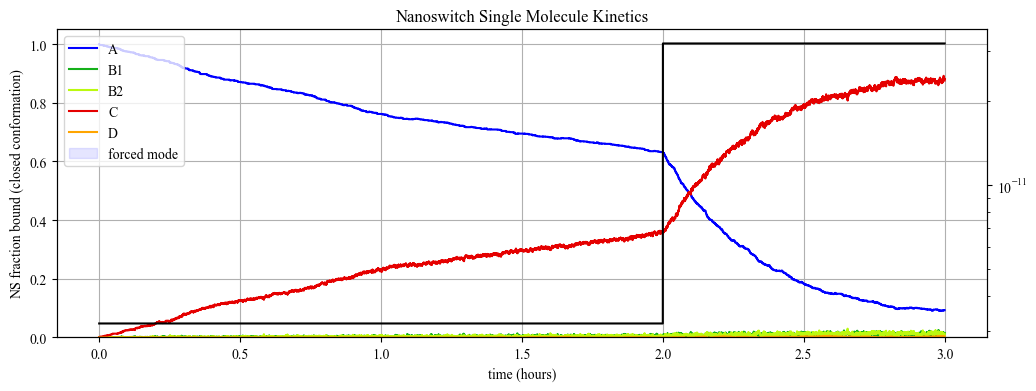

[ 631  762 1000]


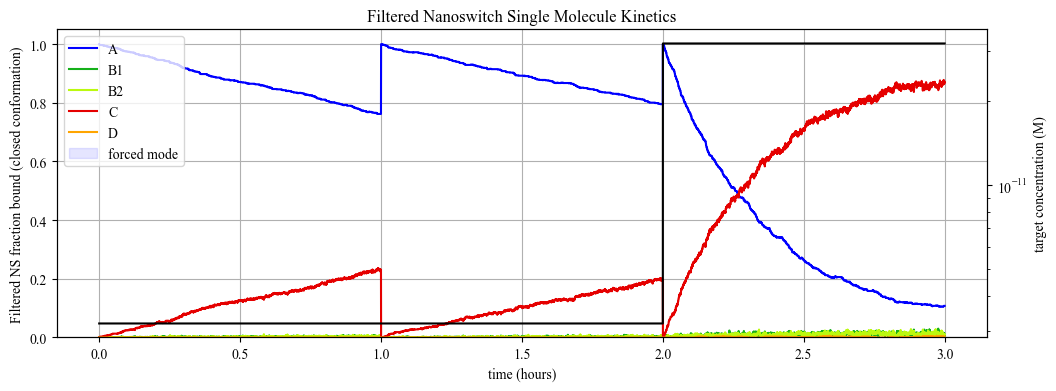

[  0 227 357]


/var/folders/cd/d23nv40n0jl90r9dhvbdfs9r0000gn/T/ipykernel_40389/2871043264.py:444: RuntimeWarning: invalid value encountered in divide
  ensemble_A_filtered_norm = ensembleA_filtered / num_filtered_particles
/var/folders/cd/d23nv40n0jl90r9dhvbdfs9r0000gn/T/ipykernel_40389/2871043264.py:445: RuntimeWarning: invalid value encountered in divide
  ensemble_B1_filtered_norm = ensembleB1_filtered / num_filtered_particles
/var/folders/cd/d23nv40n0jl90r9dhvbdfs9r0000gn/T/ipykernel_40389/2871043264.py:446: RuntimeWarning: invalid value encountered in divide
  ensemble_B2_filtered_norm = ensembleB2_filtered / num_filtered_particles
/var/folders/cd/d23nv40n0jl90r9dhvbdfs9r0000gn/T/ipykernel_40389/2871043264.py:447: RuntimeWarning: invalid value encountered in divide
  ensemble_C_filtered_norm = ensembleC_filtered / num_filtered_particles
/var/folders/cd/d23nv40n0jl90r9dhvbdfs9r0000gn/T/ipykernel_40389/2871043264.py:448: RuntimeWarning: invalid value encountered in divide
  ensemble_D_filtered_no

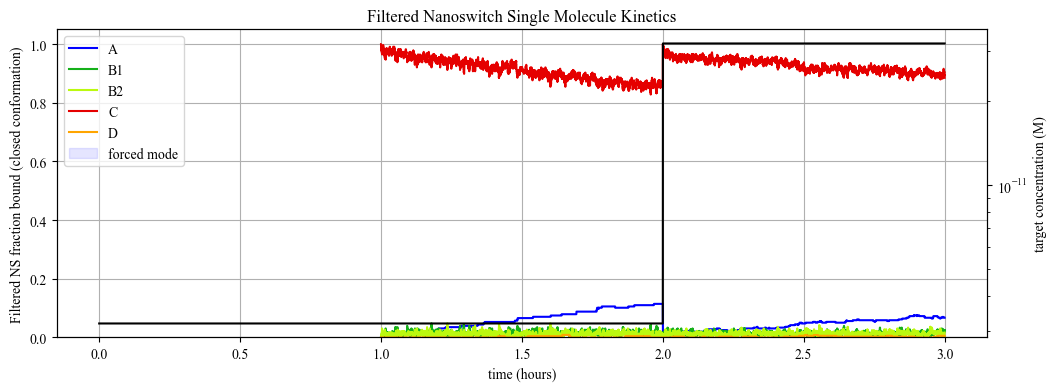

[ 643  773 1000]


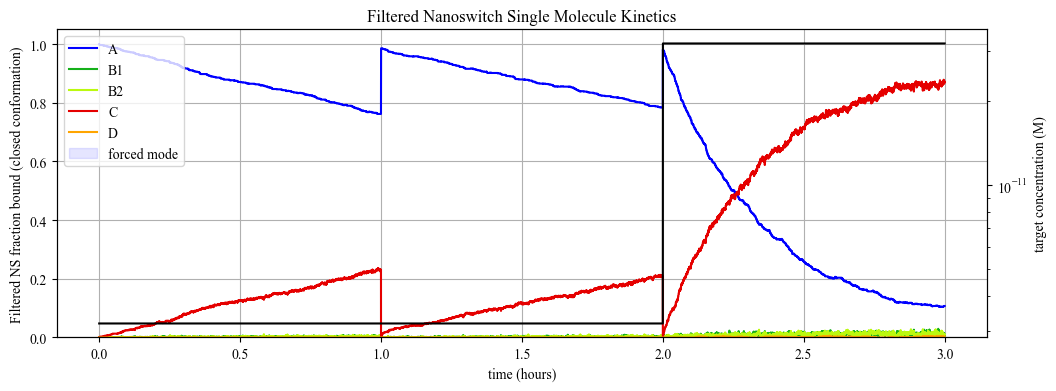

In [14]:
# time varying stochastic
kon_1 = 1.2e7 # 1/(M*s)
kon_2 = 1.2e7 # 1/(M*s)
koff_1 = 1.74e-3 #1/s
koff_2 = 1.74e-3 #1/s
C_eff = 10e-9 # M
rate_constants = [kon_1, kon_2, koff_1, koff_2, C_eff, 4*koff_1, 4*koff_2]

T_arr_test = np.asarray([[0, 60, 3.2e-12], [60, 120, 3.2e-12], [120, 180, 32e-12]]) #input as minutes for time windows, code will convert to s 
M_arr_test = np.asarray([]) #input as minutes for time windows, code will convert to s

start_state = np.zeros(n_switches)
# start_state[0:200] = 0
# start_state[200:300] = 1
# start_state[300:400] = 2
# start_state[400:500] = 3
# start_state[500:] = 4




traces_simple = simulate(n=n_switches, rates=rate_constants, start_state=start_state, duration=180*60, dt=timestep, T_array=T_arr_test, M_array=M_arr_test, sm_filter_A=True, sm_filter_C=True, sm_filter_AB1B2D=True, filter_times=[0,60,120])

# traces_homodimer = simulate(n=n_switches, rates=rate_constants, start_state=start_state, duration=240*60, dt=timestep, T_array=T_arr_test, M_array=M_arr_test, sm_filter_A=False, sm_filter_C=False, sm_filter_AB1B2D=False, filter_times=[], model="homodimer") 






In [60]:
times = np.arange(0,traces_simple.shape[1])*timestep/60
# times = np.arange(0,2000)*timestep/3600

plot_state_grid_imshow(states=traces_simple, time=times)
# plot_state_grid_imshow(states=traces_homodimer, time=times)


In [72]:
print(np.exp(4))
print(np.exp(2))

54.598150033144236
7.38905609893065


In [48]:
# # kon_1 = 1.6e6 # 1/(M*s)
# # kon_2 = 1.6e6 # 1/(M*s)
# # koff_1 = 1.24e-3 #1/s
# # koff_2 = 1.24e-3 #1/s
# kon_1 = 1.2e7 # 1/(M*s)
# kon_2 = 1.2e7 # 1/(M*s)
# koff_1 = 1.74e-3 #1/s
# koff_2 = 1.74e-3 #1/s
# C_eff = 5e-9 # M
# rate_constants = [kon_1, kon_2, koff_1, koff_2, C_eff, koff_1, koff_2]
# 
# T_arr_7_24_25_experiment = np.asarray([[0, 32, 10e-12], [32, 64, 32e-12], [64, 96, 100e-12], [96, 128, 320e-12]]) #input as minutes for time windows, code will convert to s 
# M_arr_7_24_25_experiment = np.asarray([[0, 2],[32, 34], [64, 66], [96, 98]]) #input as minutes for time windows, code will convert to s
# filter = [0, 32, 64, 96]
# 
# traces = simulate(n=n_switches, rates=rate_constants, duration=130*60, dt=timestep, T_array=T_arr_7_24_25_experiment, M_array=np.asarray([]), sm_filter_A=True, sm_filter_C=False, sm_filter_AB1B2D=True, filter_times=filter) #220*60 for 30 mins, 120*60 for 15 mins
# traces = simulate(n=n_switches, rates=rate_constants, duration=130*60, dt=timestep, T_array=T_arr_7_24_25_experiment, M_array=M_arr_7_24_25_experiment, sm_filter_A=True, sm_filter_C=False, sm_filter_AB1B2D=True, filter_times=filter) #220*60 for 30 mins, 120*60 for 15 mins
# 


TypeError: simulate() missing 1 required positional argument: 'start_state'

kon effective (1/Ms):  24000000.0
koff effective (1/s):  4.973878758008871e-05


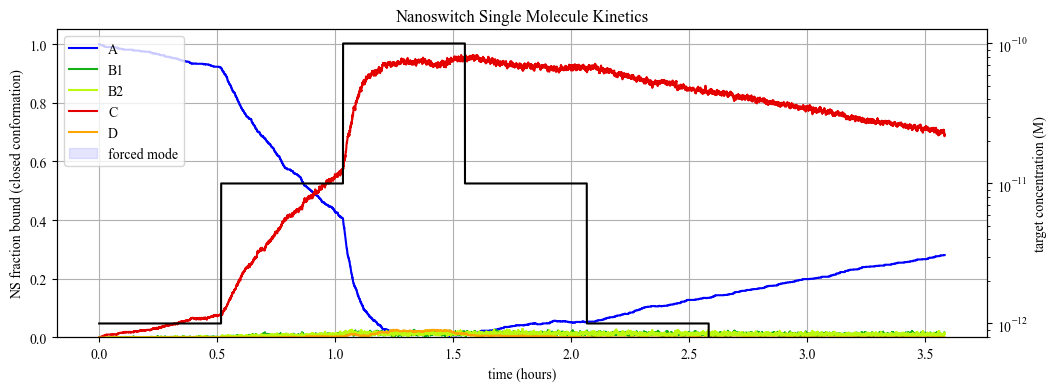

kon effective (1/Ms):  24000000.0
koff effective (1/s):  4.973878758008871e-05


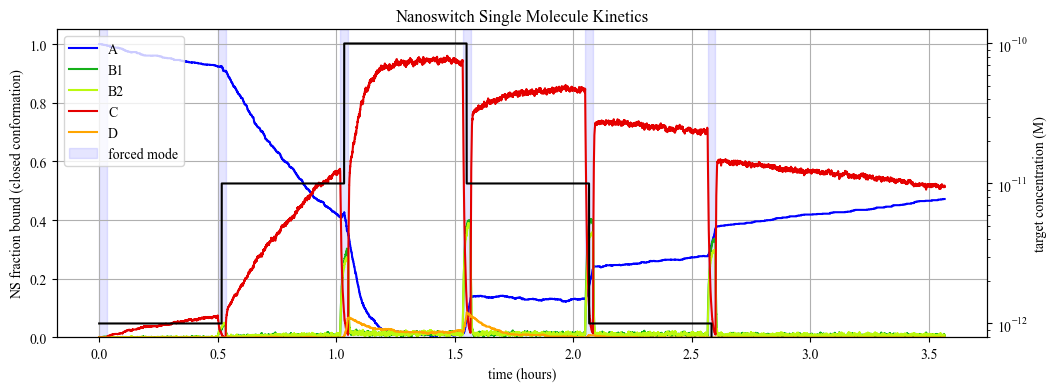

In [49]:
# 8/07/25 Experiment
# kon_1 = 1.6e6 # 1/(M*s)
# kon_2 = 1.6e6 # 1/(M*s)
# koff_1 = 1.24e-3 #1/s
# koff_2 = 1.24e-3 #1/s
kon_1 = 1.2e7 # 1/(M*s)
kon_2 = 1.2e7 # 1/(M*s)
koff_1 = 1.74e-3 #1/s
koff_2 = 1.74e-3 #1/s
C_eff = 10e-9 # M
rate_constants = [kon_1, kon_2, koff_1, koff_2, C_eff, koff_1*10, koff_2*10]
start_state = np.zeros(n_switches)

T_arr_8_07_25_experiment = np.asarray([[0, 31, 1e-12], [31, 62, 10e-12], [62, 93, 100e-12], [93, 124, 10e-12], [124, 155, 1e-12], [155, 215, 0.00]]) #input as minutes for time windows, code will convert to s 
M_arr_8_07_25_experiment = np.asarray([[0, 2], [30, 32], [61, 63], [92, 94], [123, 125], [154, 156]]) #input as minutes for time windows, code will convert to s
filter = [0, 31, 62, 93, 124, 155]

# traces = simulate(n=1000, rates=rate_constants, duration=215*60, dt=timestep, T_array=T_arr_8_07_25_experiment, M_array=np.asarray([]), sm_filter_A=False, sm_filter_C=False, sm_filter_AB1B2D=False, filter_times=filter) #220*60 for 30 mins, 120*60 for 15 mins
# traces = simulate(n=n_switches, rates=rate_constants, duration=214*60, dt=timestep, T_array=T_arr_8_07_25_experiment, M_array=M_arr_8_07_25_experiment, sm_filter_A=False, sm_filter_C=False, sm_filter_AB1B2D=False, filter_times=filter) #220*60 for 30 mins, 120*60 for 15 mins

traces = simulate(n=1000, rates=rate_constants, start_state=start_state, duration=215*60, dt=timestep, T_array=T_arr_8_07_25_experiment, M_array=np.asarray([]), sm_filter_A=False, sm_filter_C=False, sm_filter_AB1B2D=False, filter_times=filter, model="homodimer") #220*60 for 30 mins, 120*60 for 15 mins
traces = simulate(n=n_switches, rates=rate_constants, start_state=start_state, duration=214*60, dt=timestep, T_array=T_arr_8_07_25_experiment, M_array=M_arr_8_07_25_experiment, sm_filter_A=False, sm_filter_C=False, sm_filter_AB1B2D=False, filter_times=filter, model="homodimer") #220*60 for 30 mins, 120*60 for 15 mins


